# Exploring the Galaxy10 images

Before training a classifier, we need to understand the images it will learn from. This notebook looks at how many images each class has, what the galaxies look like, and how their stored pixel values vary.

We use the same data split saved in module 1: 12,359 training images, 2,650 validation images, and 2,646 test images. Image examples and image statistics use the training set. The class-count table lists all three sets so we can check their sizes. This notebook does not train a classifier.

The figures shown here are smaller copies for easier viewing. Full-size figures are in `docs/eda/figures/`.

All figures and this notebook were produced with Codex assistance; independent team confirmation is not recorded.


In [1]:
from pathlib import Path
import sys
import csv
import json
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "eda.py").is_file(), "Run from the repository root or notebooks directory"
sys.path.insert(0, str(ROOT))
import eda
from validate_eda import validate_outputs
print("Dataset version: data_v1; split seed: 42; gallery seed:", eda.SEED)
from io import BytesIO
from PIL import Image as PILImage

def show_figure(filename, width=1000):
    # Resized notebook previews; the report retains the full-resolution PNG/SVG.
    with PILImage.open(ROOT / "docs/eda/figures" / filename) as original:
        preview = original.copy()
        preview.thumbnail((width, 1800), PILImage.Resampling.LANCZOS)
        buffer = BytesIO()
        preview.save(buffer, format="PNG", optimize=True)
    display(Image(data=buffer.getvalue()))


Dataset version: data_v1; split seed: 42; gallery seed: 20261103


## Load the training-image statistics

The next cell runs the exploration script. If matching results have already been saved, the script reads them instead of calculating them again. It checks the data file, code, and saved split before reusing those results.

The output lists the number of images used. We expect 12,359 training images and zero test images. Running this cell keeps the saved data split unchanged.


In [2]:
summary = eda.run(ROOT)
print("Training images:", summary["training_count"])
print("Retained images:", summary["retained_count"])
print("Test images analyzed:", summary["test_images_analyzed"])

Training images summarized: 370/12359


Training images summarized: 1937/12359


Training images summarized: 3476/12359


Training images summarized: 5030/12359


Training images summarized: 6574/12359


Training images summarized: 8123/12359


Training images summarized: 9683/12359


Training images summarized: 11221/12359


Training images summarized: 12359/12359


{
  "training_count": 12359,
  "retained_count": 17655,
  "retained_imbalance_ratio": 7.927927927927928,
  "training_redshift_missing": 64,
  "training_redshift_negative": 1,
  "training_redshift_zero": 1
}
Training images: 12359
Retained images: 17655
Test images analyzed: 0


## How many images does each class have?

The chart and table below show the class counts after cleaning. The largest class has 2,640 images, while the smallest has 333. The largest class is about 7.93 times the size of the smallest.

This matters when we compare classifiers. A model could get many images right while still doing poorly on a small class. We will therefore report macro F1, which gives each class equal weight, and recall for each class, which shows how many of its images were correctly identified.

The table uses the saved class labels. It does not examine validation or test images.


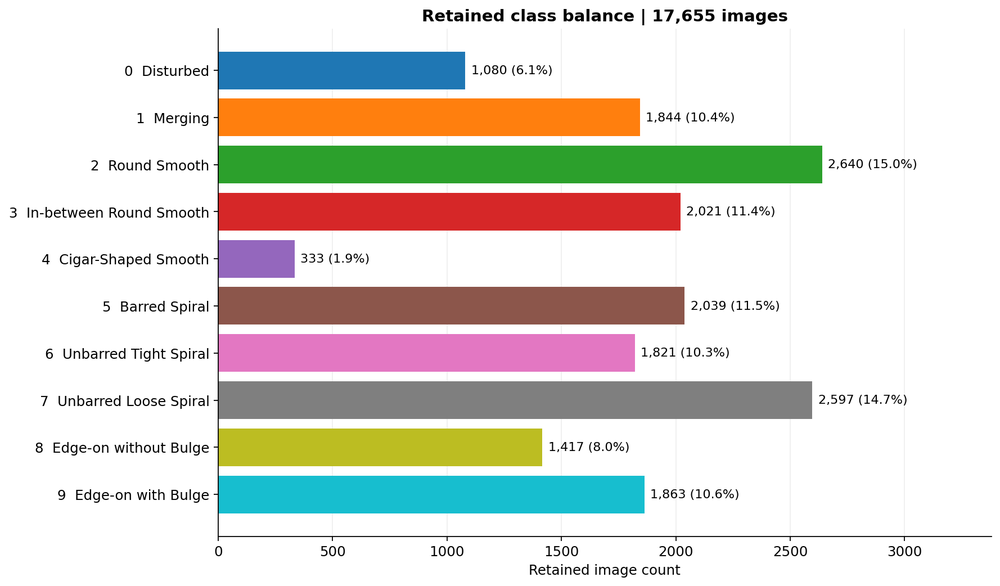

| class_id | class_name | retained | train | validation | test |
| --- | --- | --- | --- | --- | --- |
| 0 | Disturbed | 1080 | 756 | 162 | 162 |
| 1 | Merging | 1844 | 1291 | 277 | 276 |
| 2 | Round Smooth | 2640 | 1848 | 396 | 396 |
| 3 | In-between Round Smooth | 2021 | 1415 | 303 | 303 |
| 4 | Cigar-Shaped Smooth | 333 | 233 | 50 | 50 |
| 5 | Barred Spiral | 2039 | 1427 | 306 | 306 |
| 6 | Unbarred Tight Spiral | 1821 | 1275 | 273 | 273 |
| 7 | Unbarred Loose Spiral | 2597 | 1818 | 390 | 389 |
| 8 | Edge-on without Bulge | 1417 | 992 | 213 | 212 |
| 9 | Edge-on with Bulge | 1863 | 1304 | 280 | 279 |

In [3]:
show_figure("class_balance.png")
with (ROOT / "docs/eda/tables/class_counts.csv").open() as stream:
    rows = list(csv.DictReader(stream))
headers = ["class_id", "class_name", "retained", "train", "validation", "test"]
table = "| " + " | ".join(headers) + " |\n| " + " | ".join(["---"] * len(headers)) + " |\n"
table += "\n".join("| " + " | ".join(str(row[key]) for key in headers) + " |" for row in rows)
display(Markdown(table))

## What do the images look like?

The next two figures show four training images from each class. A fixed random seed makes the same examples appear each time. Each title includes the image's original row number in the data file.

Some examples contain bright neighboring objects. The galaxies also appear at different sizes. These details matter because a measurement of the whole image includes the background and nearby objects as well as the target galaxy.

Four examples give us a first look at each class. They are too few to show how often these issues occur or whether every label is correct. They also cannot tell us how well a classifier will separate the classes.


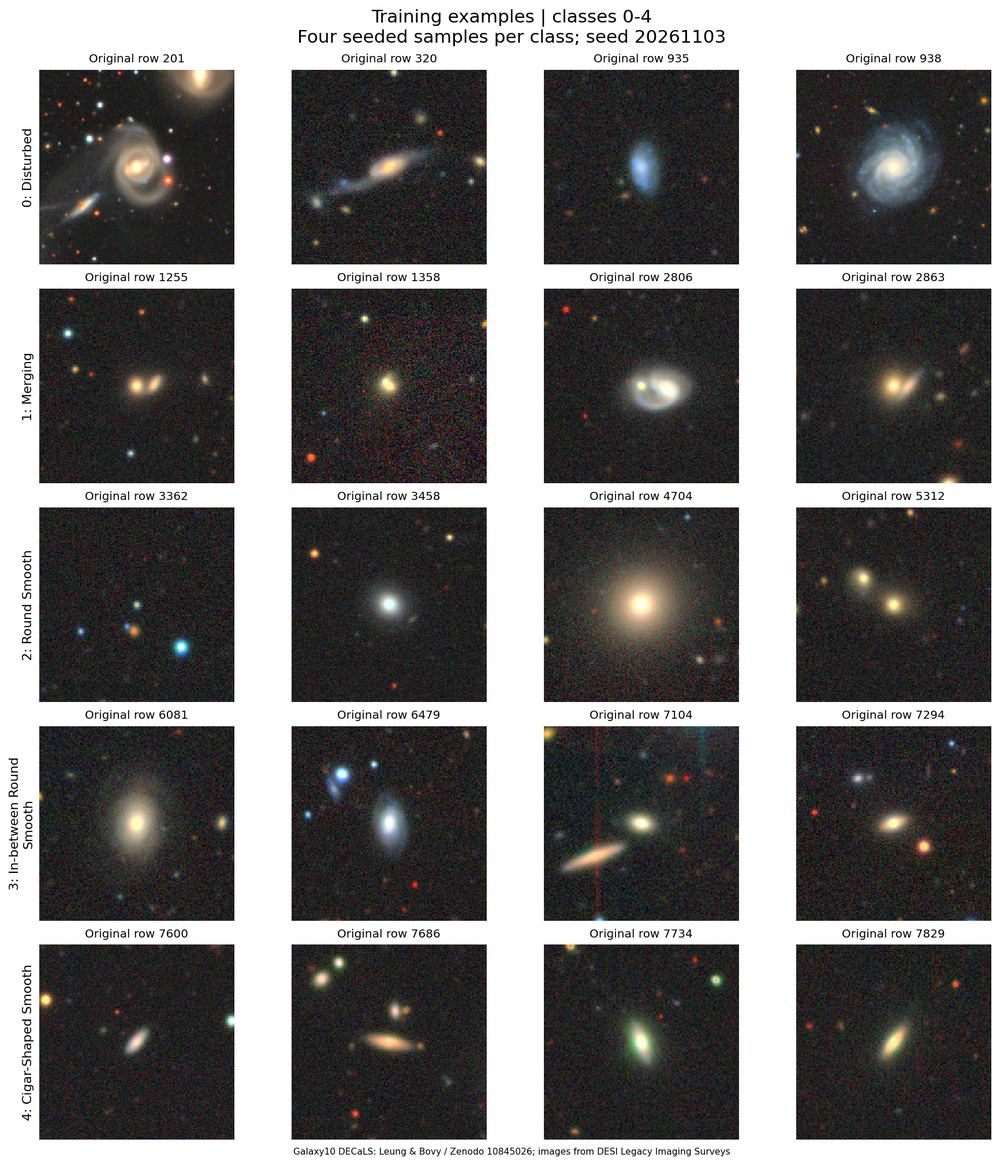

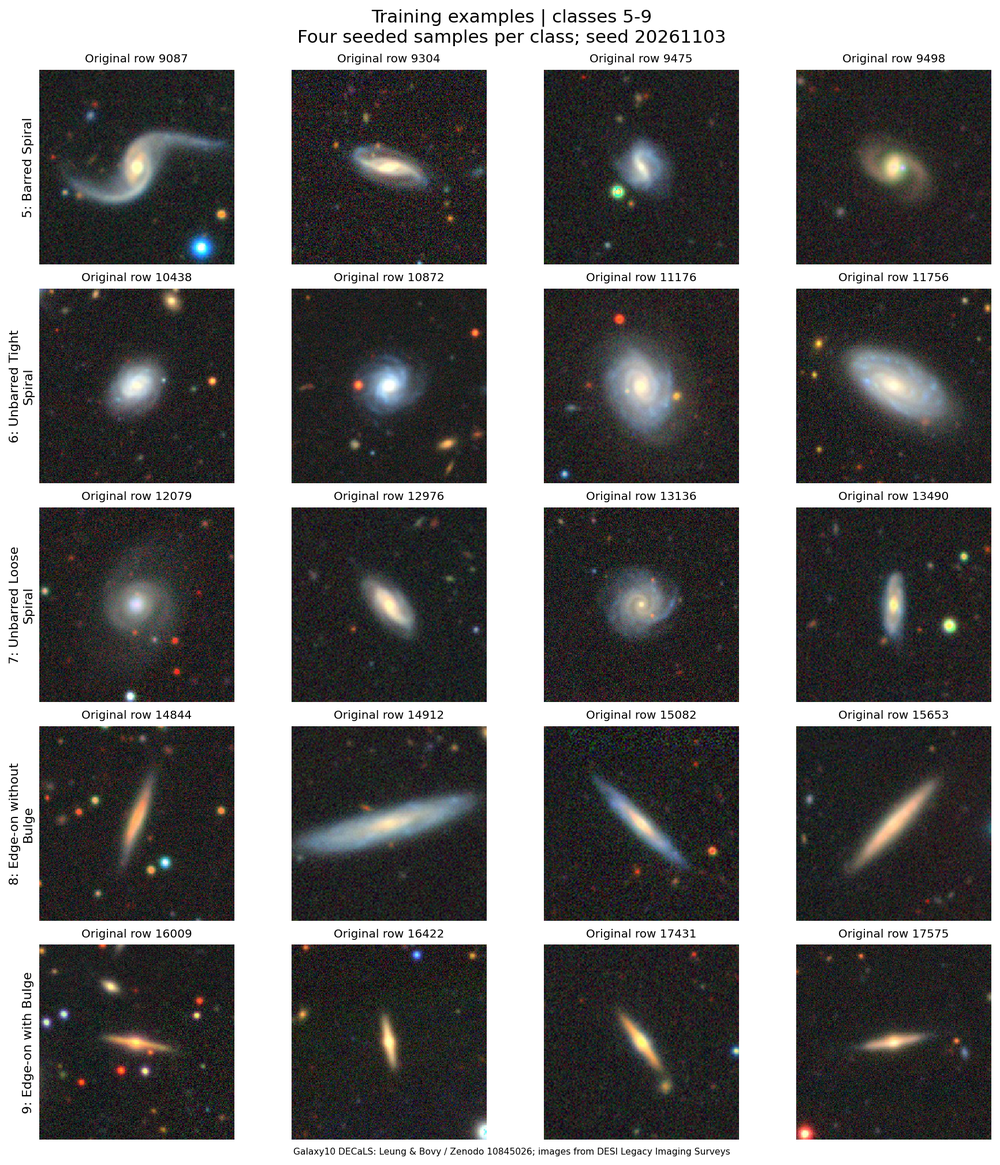

In [4]:
for filename in ["training_examples_classes_0_4.png", "training_examples_classes_5_9.png"]:
    show_figure(filename)

## What does the average image of each class show?

Each panel below is the average of all training images in one class. We use the stored pixel values without changing their contrast or rotating the galaxies into the same direction.

The average images have bright centers. Details such as spiral arms become blurred because the galaxies point in different directions. These averages help us see broad patterns, but they do not tell us how accurately individual galaxies can be classified.


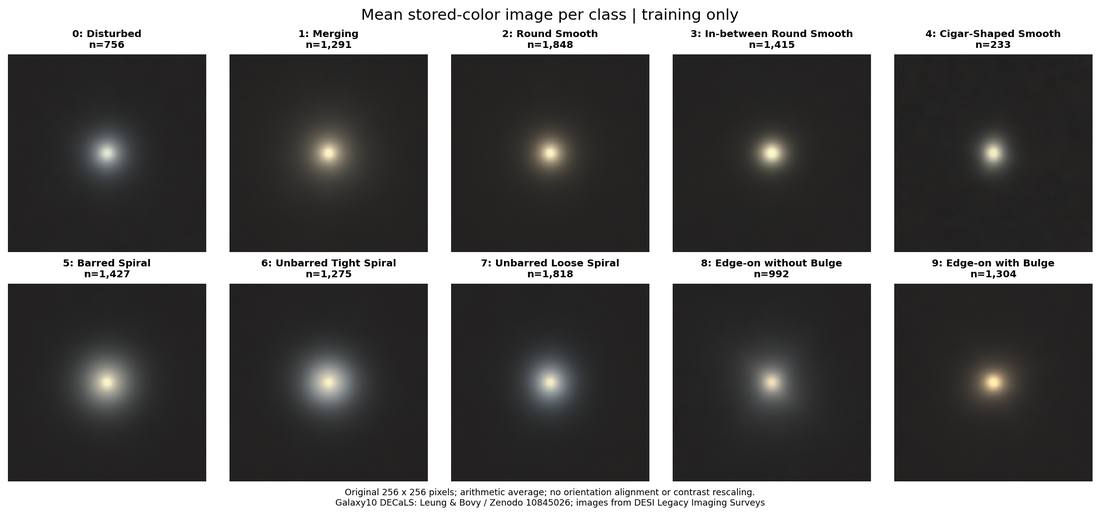

In [5]:
show_figure("training_class_means.png", width=1100)

## How do pixel values differ between classes?

The next figures compare image intensity, variation across the image, and differences between the three stored color channels.

For intensity, we average all pixel values in an image and divide by 255 to put the result on a 0-to-1 scale. To measure variation across an image, we first average the channels at each pixel, then calculate the standard deviation and divide by 255. Channel differences compare the average values of two channels.

Each box contains the middle 50% of values for a class. The lines extend to the 5th and 95th percentiles. More extreme values are left out of the drawing but remain in the saved statistics.

These measurements describe the displayed images. Measuring physical galaxy colors would require calibrated astronomical data.


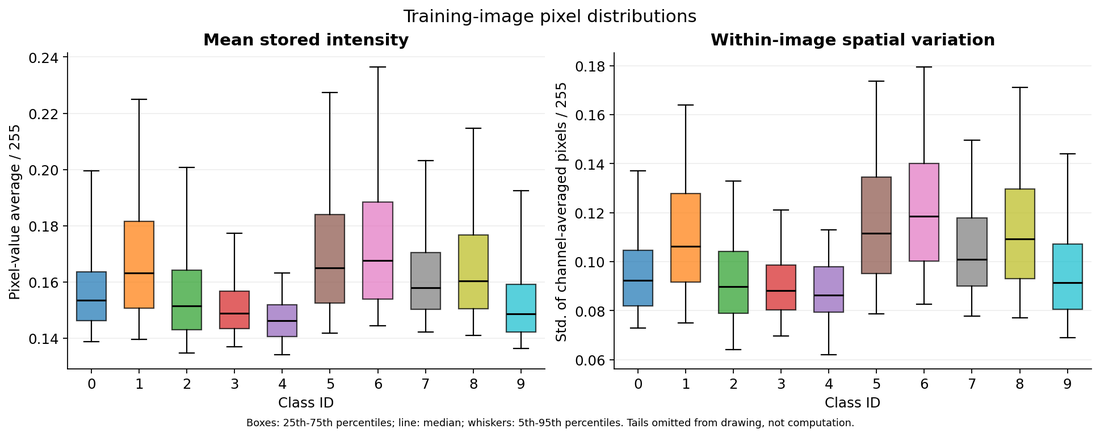

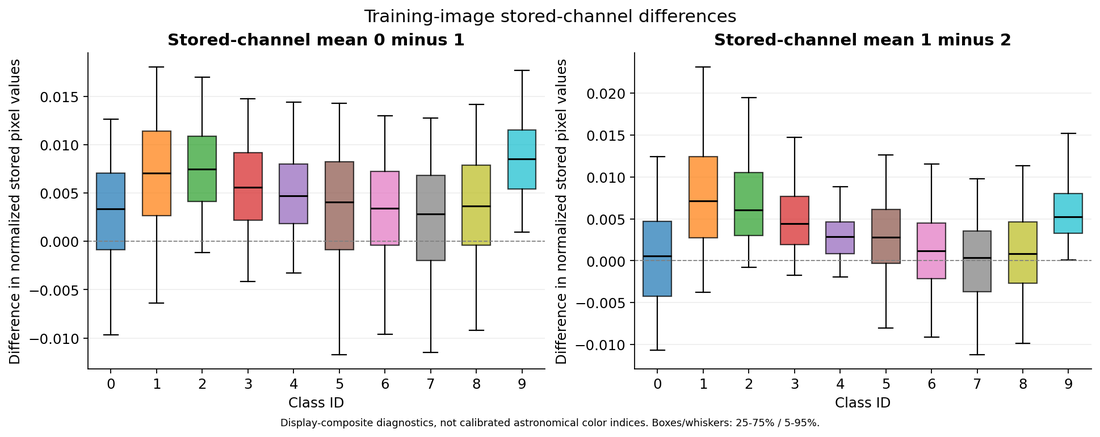

In [6]:
for filename in ["training_intensity.png", "training_channel_differences.png"]:
    show_figure(filename, width=1100)

## What extra information comes with the images?

The dataset also includes redshift and pixel scale. Redshift describes the shift of a galaxy's spectrum toward longer wavelengths. Pixel scale tells us how much of the sky one pixel covers. We inspect these fields to understand differences between the image samples; they are excluded from the main classifier inputs.

Some redshift values are missing, zero, or negative. We keep the corresponding images because the main task uses images alone. The redshift chart uses a logarithmic axis, so it shows only positive values.

Differences between classes in these plots can guide later checks. They do not explain what causes a galaxy's shape.


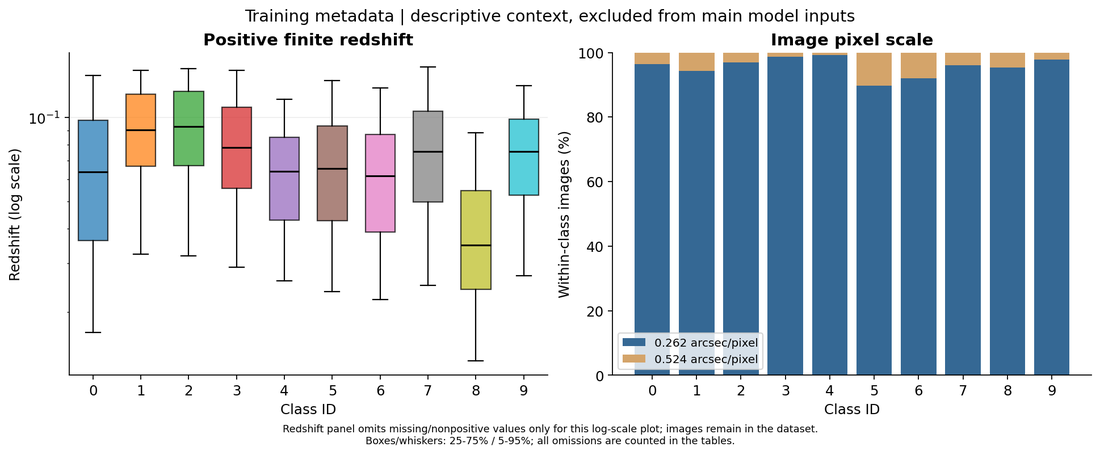

{'training_redshift_missing': 64, 'training_redshift_negative': 1, 'training_redshift_zero': 1}


In [7]:
show_figure("training_metadata.png", width=1100)
print({key: summary[key] for key in ["training_redshift_missing", "training_redshift_negative", "training_redshift_zero"]})

## Check that the figures use the intended data

The next cell checks the files and counts behind the figures. It compares class counts with the original labels, checks that example images come from the training set, and checks the pixel and redshift summaries. It also confirms that the saved figures can be opened.

File hashes act as fingerprints: they help detect changes to the data, code, or saved results. Separate tests use made-up images to check that validation and test images cannot affect training-image averages.


In [8]:
verification = validate_outputs(ROOT)
print(json.dumps(verification, indent=2))

{
  "status": "PASS",
  "training_images": 12359,
  "held_out_gallery_images": 0,
  "gallery_images": 40,
  "png_figures": 7,
  "class_count_tables_match_raw_labels": true,
  "metadata_counts_match_training_rows": true,
  "pixel_quantiles_match_local_training_statistics": true,
  "output_hashes_match": true,
  "frozen_preparation_verified": true
}


## Continue to feature extraction

This notebook describes the dataset before classifier training. The next notebook, `02_handcrafted_features.ipynb`, checks the image features created in module 3. Classifier training and comparison are still pending. No classifier, feature-reduction step, or test-set performance evaluation is run in this exploration notebook.

Data: W. Henry Leung and Jo Bovy, [Galaxy10 DECaLS](https://zenodo.org/records/10845026), under CC BY 4.0. Images come from DESI Legacy Imaging Surveys; labels come from Galaxy Zoo. We selected, arranged, and resized images for display, and calculated class averages and summary plots.

See `docs/eda/README.md` for the saved tables, methods, and limitations.
